# BC03 — Partie 2 | Choix de modèles et hyperparamètres

Prédire `retour` **au moment de la vente** (0/1). Utilisez 2025 pour entraînement + validation et 2026 **une seule fois** pour le test final. Les cellules de solution sont à compléter.

## Étape 0 — Chargement

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Cible, granularité et fuite d’information

1. `retour` est-il connu au moment de la vente ? Expliquez l’usage d’une étiquette historique.
2. Pourquoi `date_retour` et `motif_retour` sont-ils interdits comme prédicteurs au moment de la commande ?
3. Pourquoi les relevés de prix concurrents ultérieurs à la vente sont-ils dangereux pour la prédiction ?
4. Analysez les clés manquantes, les retours invalides et les doublons. Justifiez l’échantillon conservé.

In [3]:
# Même nettoyage que BC01/BC02
catalogue = produits.drop_duplicates(subset="id_produit")[["id_produit", "categorie"]]

n_brut = len(ventes)
df = ventes.drop_duplicates(subset="id_vente", keep="first")
df = df[df["id_produit"].isin(catalogue["id_produit"])]
df = df[(df["quantite"] > 0) & (df["prix_unitaire"] > 0) & (df["taux_remise"].between(0, 1))]
n_valides = len(df)

# Spécifique au ML : on ne peut apprendre que sur des étiquettes connues
print("Valeurs de retour avant filtre :")
print(df["retour"].value_counts(dropna=False))
df = df[df["retour"].isin([0, 1])].copy()
df["retour"] = df["retour"].astype(int)

df = df.merge(catalogue, on="id_produit", how="left", validate="many_to_one")

print(f"\nLignes brutes : {n_brut} → ventes valides : {n_valides} → étiquette connue : {len(df)}")
print(f"Taux de retour dans l'échantillon : {df['retour'].mean():.1%}")


Valeurs de retour avant filtre :
retour
0.0    2447
1.0     494
NaN       5
2.0       4
Name: count, dtype: int64

Lignes brutes : 3005 → ventes valides : 2950 → étiquette connue : 2941
Taux de retour dans l'échantillon : 16.8%


### Réponses — Étape 1

**1. `retour` est-il connu au moment de la vente ?** Non : le retour se produit des jours ou des semaines après la commande. On utilise donc une **étiquette historique** : sur les ventes passées dont on connaît l'issue, le modèle apprend le lien entre les caractéristiques de la commande et le retour, puis il l'applique aux nouvelles commandes pour estimer un **risque** de retour.

**2. Pourquoi `date_retour` et `motif_retour` sont-ils interdits ?** Ils n'existent **qu'après** un retour : ils sont renseignés si et seulement si `retour = 1`. Les utiliser reviendrait à donner la réponse au modèle (**fuite de la cible**) : il obtiendrait des scores quasi parfaits en entraînement, mais serait inutilisable en production, où ces champs sont toujours vides au moment de la commande.

**3. Pourquoi les relevés de prix concurrents ultérieurs sont-ils dangereux ?** Un relevé daté après la vente contient une information du **futur**, qui n'était pas disponible au moment de la décision. Le modèle serait évalué dans des conditions plus favorables que la réalité, et la performance mesurée serait trop optimiste (**fuite temporelle**). Si on utilisait ces prix, il faudrait prendre le dernier relevé **antérieur ou égal** à la date de commande. Je ne les inclus pas ici, pour rester simple et sans risque.

**4. Échantillon conservé** : mêmes règles qu'au BC01 (5 doublons supprimés ; 50 lignes exclues pour clé produit manquante ou inconnue, quantité, prix ou remise invalides), soit 2 950 ventes valides. On écarte en plus les **9 lignes à étiquette inconnue** (`retour` manquant ou égal à 2) : on ne peut pas apprendre ni évaluer sur une cible inconnue, et les corriger serait une supposition. **Échantillon final : 2 941 lignes**, avec un taux de retour d'environ 17 %. Les classes sont donc déséquilibrées : on en tiendra compte dans le choix des métriques.

## Étape 2 — Partition temporelle

1. Préparez les variables utilisables au moment de la vente (par exemple quantité, prix, remise, canal, catégorie, mois).
2. Gardez 2026 comme **test final intact**.
3. Justifiez pourquoi un mélange aléatoire 2025/2026 pourrait donner une autre estimation.

In [4]:
# Variables connues au moment de la commande
df["date_commande"] = pd.to_datetime(df["date_commande"])
df["mois"] = df["date_commande"].dt.month
df["annee"] = df["date_commande"].dt.year
df["avec_promo"] = df["code_promo"].notna().astype(int)

features_num = ["quantite", "prix_unitaire", "taux_remise", "avec_promo", "mois"]
features_cat = ["canal", "categorie"]
features = features_num + features_cat

# Partition temporelle : 2025 = entraînement/validation ; 2026 = test final (intact)
train = df[df["annee"] == 2025]
test  = df[df["annee"] == 2026]

X_train, y_train = train[features], train["retour"]
X_test,  y_test  = test[features],  test["retour"]

print(f"Train : {len(train)} lignes | {train['date_commande'].min().date()} → {train['date_commande'].max().date()} | positifs : {y_train.sum()} ({y_train.mean():.1%})")
print(f"Test  : {len(test)} lignes | {test['date_commande'].min().date()} → {test['date_commande'].max().date()} | positifs : {y_test.sum()} ({y_test.mean():.1%})")


Train : 1762 lignes | 2025-01-01 → 2025-12-31 | positifs : 286 (16.2%)
Test  : 1179 lignes | 2026-01-01 → 2026-10-31 | positifs : 208 (17.6%)


### Partition temporelle

**Variables retenues** (toutes connues au moment de la commande) : quantité, prix unitaire, taux de remise, présence d'un code promo, mois de commande (saisonnalité), canal et catégorie du produit. Sont exclues : `retour` (cible), `date_retour` et `motif_retour` (postérieurs), `id_vente` (identifiant sans valeur prédictive) et les prix concurrents (risque de fuite temporelle).

**Test final intact** : les commandes 2026 ne servent ni au prétraitement, ni à la validation croisée, ni au choix des hyperparamètres. Elles ne sont utilisées **qu'une seule fois**, à la fin.

**Pourquoi pas un mélange aléatoire 2025/2026 ?** En production, le modèle prédit **le futur à partir du passé**. Un découpage aléatoire mettrait des commandes 2026 dans l'entraînement : le modèle profiterait d'informations « futures » (évolution des prix, des comportements, de la saisonnalité 2026) et l'estimation serait **trop optimiste**. La partition temporelle simule le vrai usage et révèle une éventuelle **dérive** dans le temps (ici, le taux de retour passe de 16,2 % à 17,6 %).

## Étape 3 — Modèles et prétraitement

Comparez `DummyClassifier`, `LogisticRegression` et un troisième modèle pertinent. Utilisez un `ColumnTransformer` et une `Pipeline` pour imputer/encoder/standardiser **dans les folds** lorsque nécessaire. Expliquez la différence entre fit et transform.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Prétraitement : appris DANS chaque fold grâce à la Pipeline
preprocesseur = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler()),
    ]), features_num),
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),  # canal manquant
        ("encodage", OneHotEncoder(handle_unknown="ignore")),
    ]), features_cat),
])

modeles = {
    "Dummy (stratified)":    DummyClassifier(strategy="stratified", random_state=42),
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest":         RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                    random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metriques = ["roc_auc", "recall", "precision", "f1"]

resultats = []
for nom, modele in modeles.items():
    pipe = Pipeline([("pretraitement", preprocesseur), ("modele", modele)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metriques)
    ligne = {"modèle": nom}
    for m in metriques:
        ligne[m] = f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}"
    resultats.append(ligne)

display(pd.DataFrame(resultats).set_index("modèle"))


,roc_auc,recall,precision,f1
modèle,,,,
Dummy (stratified),0.492 ± 0.022,0.140 ± 0.037,0.148 ± 0.039,0.144 ± 0.038
Régression logistique,0.602 ± 0.016,0.535 ± 0.025,0.206 ± 0.006,0.297 ± 0.006
Random Forest,0.536 ± 0.017,0.192 ± 0.029,0.183 ± 0.027,0.187 ± 0.026


### Prétraitement et comparaison des modèles

**Pipeline** : un `ColumnTransformer` impute (médiane pour les numériques, « Inconnu » pour le canal manquant), standardise les variables numériques et encode en one-hot les variables catégorielles. Le tout est intégré à une `Pipeline` avec le modèle : à chaque fold de validation croisée, le prétraitement est **appris uniquement sur les données d'entraînement du fold**, puis appliqué à la partie validation. Aucune information de validation ne fuit dans l'apprentissage.

**fit vs transform** : `fit` **apprend** les paramètres à partir des données (médiane, moyenne et écart-type pour la standardisation, liste des modalités pour l'encodage, coefficients du modèle) ; `transform` **applique** ces paramètres déjà appris à des données, sans les recalculer. On fait `fit` sur l'entraînement seulement, puis `transform` sur la validation ou le test : sinon, on utiliserait des statistiques calculées sur des données qui devraient rester « inconnues » (fuite).

**Modèles** :
- `DummyClassifier` : prédit au hasard selon la proportion des classes. C'est la **référence minimale** à battre.
- `LogisticRegression` : modèle linéaire simple et interprétable.
- `RandomForest` : ensemble d'arbres capable de capter des interactions non linéaires (par exemple catégorie × canal).
Pour les deux derniers, `class_weight="balanced"` compense le déséquilibre des classes (~16 % de retours) : sans cela, les modèles auraient tendance à toujours prédire « pas de retour ».

**Validation** : `StratifiedKFold` à 5 folds sur 2025 uniquement, qui conserve la proportion de retours dans chaque fold.

**Résultats** : la régression logistique (ROC-AUC ≈ 0,60) bat nettement le Dummy (≈ 0,49, soit le hasard). Le Random Forest avec ses paramètres par défaut fait moins bien (≈ 0,54) : ses arbres très profonds **sur-apprennent** les données d'entraînement. On règle ce point à l'étape 4.

## Étape 4 — Hyperparamètres

Comparez au moins trois valeurs d’un hyperparamètre au moyen d’une validation croisée adaptée sur les données 2025. Justifiez la métrique de sélection. Vous pouvez utiliser `GridSearchCV`. **N’utilisez pas `X_test` ni `y_test` pour décider du meilleur paramètre.**

In [7]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([
    ("pretraitement", preprocesseur),
    ("modele", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                      random_state=42, n_jobs=-1)),
])

grille = {"modele__min_samples_leaf": [1, 5, 20, 50, 100]}

recherche = GridSearchCV(pipe_rf, grille, cv=cv, scoring="roc_auc", return_train_score=True)
recherche.fit(X_train, y_train)   # 2025 uniquement — X_test n'est PAS utilisé

resultats_gs = pd.DataFrame(recherche.cv_results_)[
    ["param_modele__min_samples_leaf", "mean_train_score", "mean_test_score", "std_test_score"]
].rename(columns={"param_modele__min_samples_leaf": "min_samples_leaf",
                  "mean_train_score": "AUC_train", "mean_test_score": "AUC_validation",
                  "std_test_score": "écart-type_validation"})
display(resultats_gs.round(3))
print("Meilleur paramètre :", recherche.best_params_, "| AUC validation :", round(recherche.best_score_, 3))


,min_samples_leaf,AUC_train,AUC_validation,écart-type_validation
0,1,1.000,0.536,0.017
1,5,0.910,0.573,0.021
2,20,0.741,0.608,0.022
3,50,0.675,0.606,0.022
4,100,0.629,0.586,0.026


Meilleur paramètre : {'modele__min_samples_leaf': 20} | AUC validation : 0.608


### Choix de l'hyperparamètre

**Hyperparamètre étudié** : `min_samples_leaf` du Random Forest, c'est-à-dire le nombre minimum de ventes dans chaque feuille d'un arbre. Plus il est grand, plus les arbres sont « simples » et moins ils mémorisent le bruit.

**Métrique de sélection : ROC-AUC.**
- Elle mesure la capacité du modèle à **classer** les ventes à risque au-dessus des autres, **indépendamment du seuil** de décision, que le métier pourra ajuster ensuite (étape 5).
- Elle est robuste au **déséquilibre des classes**, contrairement à l'accuracy : un modèle qui prédit toujours « pas de retour » aurait 84 % d'accuracy tout en étant inutile.

**Lecture** : avec `min_samples_leaf = 1`, l'AUC d'entraînement vaut 1,00 mais la validation n'atteint que 0,54 : c'est un **sur-apprentissage** typique. En augmentant le paramètre, l'écart se réduit et la validation progresse jusqu'à **0,608 pour 20**, puis redescend (100 : le modèle devient trop simple, c'est du **sous-apprentissage**).

**Modèle retenu** : Random Forest avec `min_samples_leaf = 20` (AUC validation 0,608 contre 0,602 pour la régression logistique). L'écart avec la régression logistique est faible, inférieur à l'écart-type entre folds (≈ 0,02) : les deux modèles sont quasiment équivalents. On garde la règle fixée à l'avance (meilleure AUC en validation croisée). Le choix est fait **sans regarder les données 2026**.

## Étape 5 — Évaluation finale

Après avoir arrêté les choix, évaluez **une seule fois** sur 2026 : matrice de confusion, précision, rappel, F1, et ROC-AUC si des scores probabilistes sont disponibles. Interprétez FP et FN du point de vue CycleNova.

               precision    recall  f1-score   support

Pas de retour      0.854     0.598     0.704       971
       Retour      0.218     0.524     0.308       208

     accuracy                          0.585      1179
    macro avg      0.536     0.561     0.506      1179
 weighted avg      0.742     0.585     0.634      1179

ROC-AUC test 2026 : 0.589
Taux de retour réel en 2026 (précision d'un tirage au hasard) : 0.176


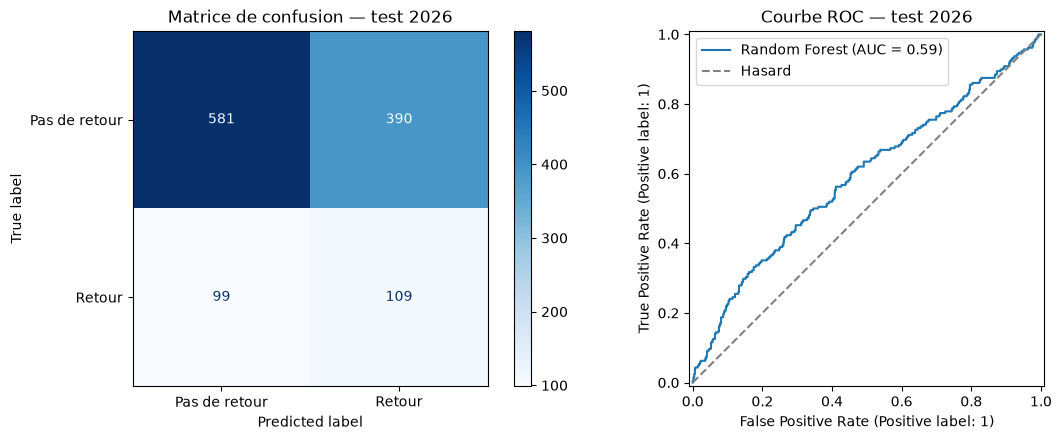

In [8]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, RocCurveDisplay)
import matplotlib.pyplot as plt

modele_final = recherche.best_estimator_   # déjà réentraîné sur tout 2025 par GridSearchCV

y_pred  = modele_final.predict(X_test)
y_score = modele_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Pas de retour", "Retour"], digits=3))
print(f"ROC-AUC test 2026 : {roc_auc_score(y_test, y_score):.3f}")
print(f"Taux de retour réel en 2026 (précision d'un tirage au hasard) : {y_test.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Pas de retour", "Retour"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Matrice de confusion — test 2026")
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
axes[1].legend(); axes[1].set_title("Courbe ROC — test 2026")
plt.tight_layout(); plt.show()


### Résultats sur le test 2026 (évaluation unique)

| Métrique (classe « Retour ») | Valeur |
|---|---|
| Rappel | 0,524 (109 retours détectés sur 208) |
| Précision | 0,218 |
| F1 | 0,308 |
| ROC-AUC | 0,589 |

Matrice de confusion : 581 vrais négatifs, **390 faux positifs**, **99 faux négatifs**, 109 vrais positifs.

L'AUC test (0,589) est proche de l'AUC de validation (0,608) : la **légère baisse** est cohérente avec un changement de période, sans signe de sur-apprentissage grave. Le modèle fait mieux que le hasard (précision de 21,8 % contre 17,6 % pour un tirage aléatoire), mais le **pouvoir prédictif reste faible**.

**Lecture métier pour CycleNova**
- **Faux positif (390)** : une commande signalée « à risque » qui n'est finalement pas retournée. Coût : une action inutile (appel, guide des tailles, contrôle), voire une **friction pour un client** de bonne foi si l'action est intrusive (blocage, frais).
- **Faux négatif (99)** : un retour non anticipé. Coût : logistique inverse, remboursement, produit éventuellement invendable (défectueux), soit le coût que l'on cherchait à éviter.
- Avec ce modèle, **près de 4 alertes sur 5 sont des fausses alertes**. Il ne convient donc qu'à des **actions préventives peu coûteuses et non bloquantes** (par exemple afficher un guide des tailles ou un rappel de vérification). Le seuil de décision (0,5 par défaut) pourra être ajusté selon le rapport de coûts FP/FN fixé par le métier.

## Étape 6 — Recommandation

Présentez le modèle retenu, sa performance hors échantillon, les risques de dérive dans le temps et les limites de la décision automatisée.

### Recommandation

**Modèle retenu** : Random Forest (300 arbres, `min_samples_leaf = 20`, classes pondérées), intégré dans une Pipeline de prétraitement, entraîné sur les commandes 2025.

**Performance hors échantillon (2026)** : ROC-AUC 0,59, rappel 52 %, précision 22 %. Le modèle détecte environ la moitié des retours, mais avec beaucoup de fausses alertes. **Le signal disponible au moment de la commande est faible** : quantité, prix, remise, canal, catégorie et mois expliquent peu le retour. Le modèle est meilleur que le hasard, mais pas assez fiable pour automatiser des décisions engageantes.

**Usage recommandé** : un **score d'aide à la décision**, utilisé pour des actions préventives à faible coût (conseils de taille sur les chaussures et le textile, vérification du produit avant expédition), et **non** pour bloquer ou pénaliser une commande.

**Risques de dérive dans le temps**
- Le taux de retour évolue (16,2 % en 2025 contre 17,6 % en 2026) et le CA baisse en 2026 : les comportements changent.
- Évolutions possibles des canaux, des promotions, du catalogue (nouvelles catégories) ou de la politique de retour.
- Mesures : suivi mensuel de l'AUC et du rappel, contrôle de la distribution des variables, **réentraînement périodique** (par exemple trimestriel), en conservant toujours une période de test postérieure.

**Limites de la décision automatisée**
- Pas de variables client (historique de retours, taille habituelle) : c'est probablement la principale source de signal manquante. Leur ajout devrait respecter le **RGPD** (minimisation, information des clients).
- Risque d'**injustice** : pénaliser des clients sur la base d'un score imprécis. Le RGPD (article 22) encadre les décisions entièrement automatisées produisant des effets significatifs : une **supervision humaine** est nécessaire.
- Données observationnelles, étiquettes historiques imparfaites (9 lignes à étiquette inconnue exclues) et un seul découpage temporel évalué.

**Pistes d'amélioration** : ajouter des variables disponibles à la commande (historique client pseudonymisé, taille commandée, délai de livraison annoncé), tester un modèle de gradient boosting, et ajuster le seuil de décision à partir d'une estimation chiffrée des coûts FP/FN avec les équipes produit et support.